# Support Vector Machines (SVM) - Phân loại biên mềm (Soft Margin)

Khác với Logistic Regression hay Perceptron chỉ cố gắng tìm *một* đường thẳng chia cắt dữ liệu, SVM tối ưu hóa để tìm ra đường thẳng có **lề (margin) rộng nhất**. Đường thẳng này cách đều các điểm dữ liệu gần nhất (gọi là các Support Vectors) của cả 2 lớp.

**1. Hàm mục tiêu (Primal Form):**
SVM nhãn dữ liệu là $y \in \{-1, 1\}$. Mục tiêu là cực tiểu hóa hàm chi phí kết hợp giữa độ lớn của trọng số (để tối đa hóa lề) và tổng lỗi vi phạm lề (Hinge Loss):
$$\mathcal{L}(w, b) = \frac{1}{2} ||w||_2^2 + C \frac{1}{N} \sum_{i=1}^N \max(0, 1 - y_i (w^T x_i + b))$$
*   Hạng tử $\frac{1}{2} ||w||^2$: L2 Regularization, ép độ lớn trọng số nhỏ xuống để mở rộng lề.
*   Hạng tử Hinge Loss $\max(0, 1 - y_i \hat{y}_i)$: Phạt các điểm nằm sai phía hoặc nằm lọt vào trong vùng lề (margin < 1).
*   Tham số $C$: Cân bằng giữa việc tối đa hóa lề (C nhỏ) và hạn chế phân loại sai (C lớn).

**2. Gradient Descent:**
Đạo hàm của hàm Hinge Loss:
*   Nếu $y_i (w^T x_i + b) \ge 1$ (Điểm nằm an toàn ngoài lề): $\nabla_w = w$, $\nabla_b = 0$
*   Nếu $y_i (w^T x_i + b) < 1$ (Điểm vi phạm lề): $\nabla_w = w - C \cdot y_i x_i$, $\nabla_b = -C \cdot y_i$

In [1]:
import numpy as np

class LinearSVM_GD:
    """Máy Vector Hỗ Trợ tuyến tính tối ưu bằng Gradient Descent (Hinge Loss)."""
    def __init__(self, learning_rate=0.01, C=1.0, epochs=1000):
        self.lr = learning_rate
        self.C = C
        self.epochs = epochs
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X: np.ndarray, y: np.ndarray):
        X = np.asarray(X)
        # Bắt buộc chuyển nhãn {0, 1} thành {-1, 1} cho hàm Hinge Loss
        y_ = np.where(y <= 0, -1, 1)
        N, D = X.shape
        
        # Khởi tạo trọng số ngẫu nhiên nhỏ
        np.random.seed(42)
        self.w = np.random.randn(D) * 0.01
        self.b = 0.0

        for _ in range(self.epochs):
            # Tính margin: y_i * (w^T x_i + b)
            margins = y_ * (np.dot(X, self.w) + self.b)
            
            # Lưu lịch sử Loss = L2 + C * HingeLoss
            hinge_loss = np.maximum(0, 1 - margins)
            loss = 0.5 * np.dot(self.w, self.w) + self.C * np.mean(hinge_loss)
            self.loss_history.append(loss)
            
            # Mask tìm các điểm vi phạm lề (margin < 1)
            # Chỉ các điểm này mới tạo ra gradient cho hạng tử Hinge Loss
            mask = (margins < 1).astype(float)
            
            # Tính Gradient gộp trên toàn bộ batch
            grad_w = self.w - (self.C / N) * np.dot(X.T, y_ * mask)
            grad_b = - (self.C / N) * np.sum(y_ * mask)
            
            # Cập nhật trọng số
            self.w -= self.lr * grad_w
            self.b -= self.lr * grad_b
            
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        linear_output = np.dot(X, self.w) + self.b
        # Chuyển ngược lại về nhãn {0, 1}
        return np.where(linear_output >= 0.0, 1, 0)

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 1.0000          | 1.0000         
Time (ms)            | 33.80           | 17.55          


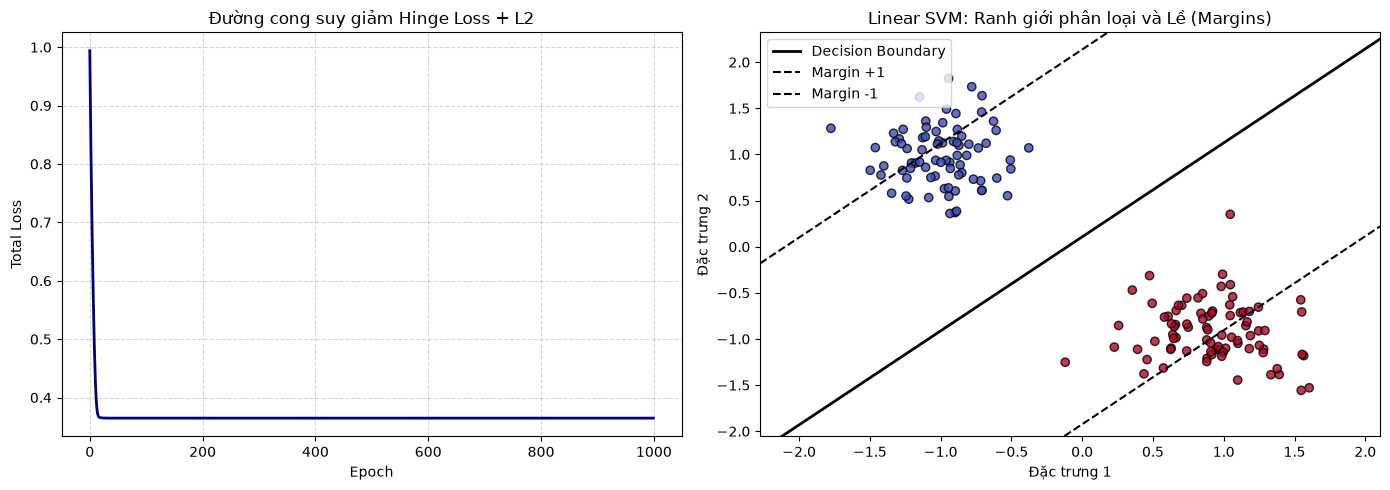

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs
from utils.metrics import accuracy_score
from utils.preprocessing import StandardScaler, train_test_split

# 1. Sinh dữ liệu (Tạo khoảng cách vừa phải để thấy các điểm Support Vector)
X, y = make_blobs(n_samples=200, centers=2, n_features=2, random_state=42, cluster_std=1.2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Chuẩn hóa dữ liệu (Tối quan trọng với thuật toán tính Margin như SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện model Scratch
t0 = time.time()
# C=1.0 là mức phạt tiêu chuẩn
model_scratch = LinearSVM_GD(learning_rate=0.05, C=1.0, epochs=1000).fit(X_train_scaled, y_train)
t_scratch = (time.time() - t0) * 1000

# 4. Huấn luyện model Sklearn
t0 = time.time()
model_sklearn = SVC(kernel='linear', C=1.0, random_state=42).fit(X_train_scaled, y_train)
t_sklearn = (time.time() - t0) * 1000

# 5. Đánh giá
y_pred_scratch = model_scratch.predict(X_test_scaled)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 6. Trực quan hóa đường biên và hai lề (margins)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Loss Curve
ax1.plot(model_scratch.loss_history, color='navy', lw=2)
ax1.set_title("Đường cong suy giảm Hinge Loss + L2")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Total Loss")
ax1.grid(True, linestyle='--', alpha=0.5)

# Đồ thị 2: Cắt ngang ranh giới và lề (Margins)
ax2.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)

# Tạo lưới để vẽ đường thẳng
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
xx = np.linspace(x_min, x_max, 100)

# Trục y của đường biên chính (w0*x + w1*y + b = 0) => y = (-w0*x - b) / w1
w = model_scratch.w
b = model_scratch.b
yy_main = (-w[0] * xx - b) / w[1]

# Hai đường lề trên/dưới (w0*x + w1*y + b = 1 hoặc -1) => y = (-w0*x - b +/- 1) / w1
yy_up = (-w[0] * xx - b + 1) / w[1]
yy_down = (-w[0] * xx - b - 1) / w[1]

ax2.plot(xx, yy_main, 'k-', lw=2, label='Decision Boundary')
ax2.plot(xx, yy_up, 'k--', lw=1.5, label='Margin +1')
ax2.plot(xx, yy_down, 'k--', lw=1.5, label='Margin -1')

ax2.set_xlim(x_min, x_max)
ax2.set_ylim(X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5)
ax2.set_title("Linear SVM: Ranh giới phân loại và Lề (Margins)")
ax2.set_xlabel("Đặc trưng 1")
ax2.set_ylabel("Đặc trưng 2")
ax2.legend()

plt.tight_layout()
plt.show()